# Natural Language Processing: summarization, search, representation, and similarity

# Loading texts from the Internet

In [1]:
# !pip install spacy --upgrade

In [2]:
import spacy
spacy.__version__

'3.8.16'

In [3]:
# !python -m spacy download en_core_web_sm

In [4]:
import en_core_web_sm

In [5]:
# !pip install goose3

In [6]:
from goose3 import Goose
from bs4 import BeautifulSoup
from pathlib import Path
from types import SimpleNamespace
import json
import requests

url = 'https://en.wikipedia.org/wiki/Natural_language_processing'
# Resolve the cache whether the kernel starts at the repo root or beside this notebook.
notebook_dir = Path.cwd()
if (notebook_dir / '65.The-Ultimate-Beginners-Guide-to-Natural-Language-Processing').is_dir():
  notebook_dir /= '65.The-Ultimate-Beginners-Guide-to-Natural-Language-Processing'
cache_file = notebook_dir / 'Resources' / 'natural_language_processing.json'

def load_article(url, cache_file):
  try:
    response = requests.get(url, headers={'User-Agent': 'NLP-Tutorial/1.0 (educational article extraction)'}, timeout=20)
    response.raise_for_status()
    soup = BeautifulSoup(response.text, 'html.parser')
    with Goose() as g:
      extracted = g.extract(raw_html=response.text)
    text = extracted.cleaned_text.strip()
    if not text:
      # Wikipedia's layout can leave Goose with an empty cleaned_text.
      content = soup.select_one('.mw-parser-output') or soup.select_one('main')
      if content is None:
        raise ValueError('Article content was not found in the response')
      for element in content.select('sup.reference, script, style, table, .navbox, .reflist'):
        element.decompose()
      paragraphs = [p.get_text(' ', strip=True) for p in content.find_all('p')]
      text = '\n\n'.join(p for p in paragraphs if p)
    if not text:
      raise ValueError('The page contains no readable article text')
    heading = soup.select_one('#firstHeading') or soup.find('h1')
    title = heading.get_text(' ', strip=True) if heading else extracted.title
    data = {'title': title or 'Natural language processing', 'cleaned_text': text,
            'authors': extracted.authors, 'links': extracted.links, 'source_url': url}
  except (requests.RequestException, ValueError) as exc:
    if not cache_file.exists():
      raise RuntimeError('Could not load the article and no local copy is available. Check your connection and rerun this cell.') from exc
    data = json.loads(cache_file.read_text(encoding='utf-8'))
    if data.get('source_url') != url or not data.get('cleaned_text', '').strip():
      raise ValueError('The cached article is empty or belongs to another URL') from exc
    print('Using the saved Wikipedia article because the live request was unavailable.')
  else:
    cache_file.parent.mkdir(parents=True, exist_ok=True)
    cache_file.write_text(json.dumps(data, ensure_ascii=False, indent=2), encoding='utf-8')
    print('Loaded article from Wikipedia (saved a local copy).')
  return SimpleNamespace(**data)

article = load_article(url, cache_file)
print(f'{article.title}: {len(article.cleaned_text):,} characters')

Loaded article from Wikipedia (saved a local copy).
Natural language processing: 7,039 characters


In [7]:
article.title

'Natural language processing'

In [8]:
article.cleaned_text

'Natural language processing ( NLP ) is the processing of natural language information by a computer . NLP is a subfield of computer science and is closely associated with artificial intelligence . NLP is also related to information retrieval , knowledge representation , computational linguistics , and linguistics more broadly.\n\nMajor processing tasks in an NLP system include: speech recognition , text classification , natural language understanding , and natural language generation .\n\nNatural language processing has its roots in the 1950s. Already in 1950, Alan Turing published an article titled " Computing Machinery and Intelligence ," which proposed what is now called the Turing test as a criterion of intelligence, though at the time that was not articulated as a problem separate from artificial intelligence. The proposed test includes a task that involves the automated interpretation and generation of natural language.\n\nThe premise of symbolic NLP is often illustrated using J

In [9]:
article.authors

['Contributors to Wikimedia projects']

In [10]:
article.links

['https://en.wikipedia.org/wiki/Special:EditPage/Natural_language_processing',
 'https://en.wikipedia.org/wiki/Talk:Natural_language_processing',
 'https://en.wikipedia.org/wiki/Help:Maintenance_template_removal',
 'https://en.wikipedia.org/wiki/File:Question_book-new.svg',
 'https://en.wikipedia.org/wiki/Wikipedia:Verifiability',
 'https://www.google.com/search?as_eq=wikipedia&q=%22Natural+language+processing%22',
 'https://www.google.com/search?tbm=nws&q=%22Natural+language+processing%22+-wikipedia&tbs=ar:1',
 'https://www.google.com/search?&q=%22Natural+language+processing%22&tbs=bkt:s&tbm=bks',
 'https://www.google.com/search?tbs=bks:1&q=%22Natural+language+processing%22+-wikipedia',
 'https://scholar.google.com/scholar?q=%22Natural+language+processing%22',
 'https://www.jstor.org/action/doBasicSearch?Query=%22Natural+language+processing%22&acc=on&wc=on',
 'https://en.wikipedia.org/wiki/Special:EditPage/Natural_language_processing',
 'https://en.wikipedia.org/wiki/Help:Referencing_

# Named entity recognition

In [11]:
nlp = spacy.load('en_core_web_sm')
nlp

In [12]:
document = nlp(article.cleaned_text)

In [13]:
# Tags: https://ashutoshtripathi.com/2020/04/13/parts-of-speech-tagging-and-dependency-parsing-using-spacy-nlp/
for token in document:
  print(token.text, ' - ', token.pos_)

Natural  -  ADJ
language  -  NOUN
processing  -  NOUN
(  -  PUNCT
NLP  -  PROPN
)  -  PUNCT
is  -  AUX
the  -  DET
processing  -  NOUN
of  -  ADP
natural  -  ADJ
language  -  NOUN
information  -  NOUN
by  -  ADP
a  -  DET
computer  -  NOUN
.  -  PUNCT
NLP  -  PROPN
is  -  AUX
a  -  DET
subfield  -  NOUN
of  -  ADP
computer  -  NOUN
science  -  NOUN
and  -  CCONJ
is  -  AUX
closely  -  ADV
associated  -  VERB
with  -  ADP
artificial  -  ADJ
intelligence  -  NOUN
.  -  PUNCT
NLP  -  PROPN
is  -  AUX
also  -  ADV
related  -  VERB
to  -  ADP
information  -  NOUN
retrieval  -  NOUN
,  -  PUNCT
knowledge  -  NOUN
representation  -  NOUN
,  -  PUNCT
computational  -  ADJ
linguistics  -  NOUN
,  -  PUNCT
and  -  CCONJ
linguistics  -  NOUN
more  -  ADV
broadly  -  ADV
.  -  PUNCT


  -  SPACE
Major  -  ADJ
processing  -  NOUN
tasks  -  NOUN
in  -  ADP
an  -  DET
NLP  -  PROPN
system  -  NOUN
include  -  VERB
:  -  PUNCT
speech  -  NOUN
recognition  -  NOUN
,  -  PUNCT
text  -  NOUN
classificati

In [14]:
from spacy import displacy
displacy.render(document, style = 'ent', jupyter=True)

In [15]:
for entity in document.ents:
  if entity.label_ == 'PERSON':
    print(entity.text)

Alan Turing
John Searle's
Moore
Symbolic
Markov
George Lakoff
Karl J. Friston


# Most frequent words

In [16]:
import nltk

In [17]:
nltk.download('punkt')

[nltk_data] Downloading package punkt to /Users/ankit/nltk_data...
[nltk_data]   Package punkt is already up-to-date!


True

In [18]:
tokens = nltk.tokenize.word_tokenize(article.cleaned_text)

In [19]:
tokens

['Natural',
 'language',
 'processing',
 '(',
 'NLP',
 ')',
 'is',
 'the',
 'processing',
 'of',
 'natural',
 'language',
 'information',
 'by',
 'a',
 'computer',
 '.',
 'NLP',
 'is',
 'a',
 'subfield',
 'of',
 'computer',
 'science',
 'and',
 'is',
 'closely',
 'associated',
 'with',
 'artificial',
 'intelligence',
 '.',
 'NLP',
 'is',
 'also',
 'related',
 'to',
 'information',
 'retrieval',
 ',',
 'knowledge',
 'representation',
 ',',
 'computational',
 'linguistics',
 ',',
 'and',
 'linguistics',
 'more',
 'broadly',
 '.',
 'Major',
 'processing',
 'tasks',
 'in',
 'an',
 'NLP',
 'system',
 'include',
 ':',
 'speech',
 'recognition',
 ',',
 'text',
 'classification',
 ',',
 'natural',
 'language',
 'understanding',
 ',',
 'and',
 'natural',
 'language',
 'generation',
 '.',
 'Natural',
 'language',
 'processing',
 'has',
 'its',
 'roots',
 'in',
 'the',
 '1950s',
 '.',
 'Already',
 'in',
 '1950',
 ',',
 'Alan',
 'Turing',
 'published',
 'an',
 'article',
 'titled',
 '``',
 'Comput

In [20]:
len(tokens)

1154

In [21]:
frequency = nltk.FreqDist(tokens)
most_common = frequency.most_common(50)
most_common

[(',', 70),
 ('the', 51),
 ('of', 49),
 ('.', 42),
 ('and', 28),
 ('in', 22),
 ('a', 20),
 ('language', 18),
 ('NLP', 17),
 ('is', 17),
 ('to', 14),
 ('(', 12),
 (')', 12),
 ('processing', 11),
 ('natural', 11),
 ('cognitive', 11),
 ('by', 10),
 ('with', 10),
 ('linguistics', 9),
 ('tasks', 8),
 (':', 8),
 ('that', 8),
 ('are', 8),
 ('as', 7),
 ('approach', 7),
 ('word', 7),
 ('rules', 6),
 ('on', 6),
 ('approaches', 6),
 ('statistical', 6),
 ('have', 6),
 ('words', 6),
 ('intelligence', 5),
 ('an', 5),
 ('text', 5),
 ('was', 5),
 ('The', 5),
 ('e.g.', 5),
 ('for', 5),
 ('used', 5),
 ('artificial', 4),
 ('knowledge', 4),
 ('computational', 4),
 ('or', 4),
 ('based', 4),
 ('grammar', 4),
 ('computer', 3),
 ('science', 3),
 ('understanding', 3),
 ('its', 3)]

# Word cloud

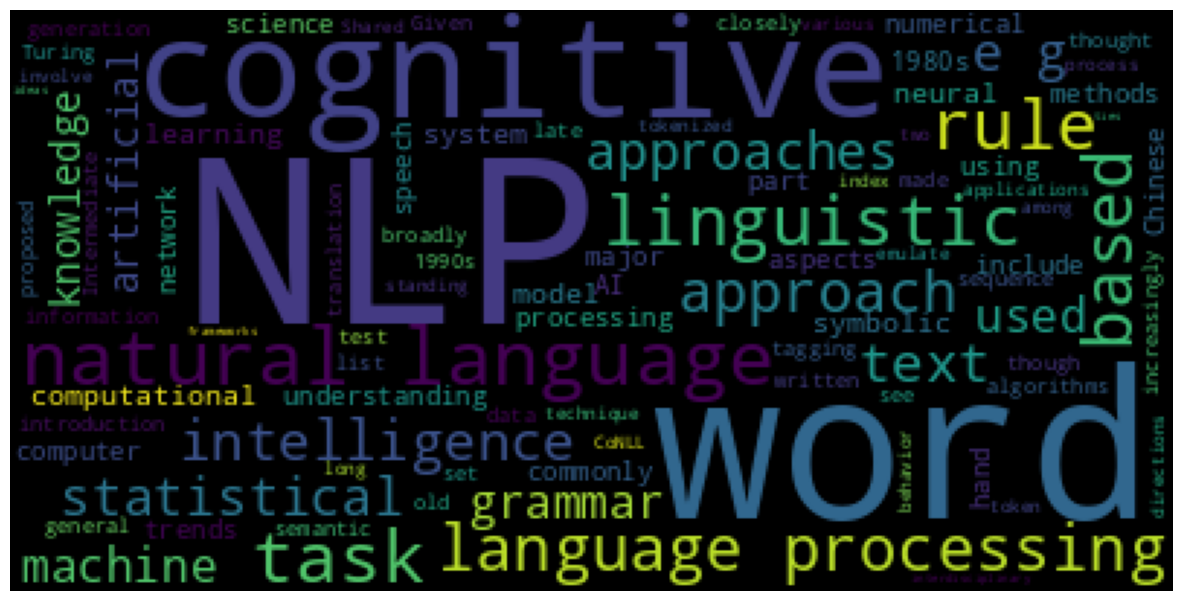

In [22]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt
cloud = WordCloud()
cloud = cloud.generate(article.cleaned_text)
plt.figure(figsize=(15,15))
plt.imshow(cloud)
plt.axis('off');

# Preprocessing the texts (frequency and word cloud)

In [23]:
def preprocessing(sentence):
  # a A
  sentence = sentence.lower()
  sentence = sentence.replace('.', '')
  tokens = []
  tokens = [token.text for token in nlp(sentence) if not (token.is_stop or token.like_num or token.is_punct or token.is_space or len(token) == 1)]
  tokens = ' '.join([element for element in tokens])

  return tokens

In [24]:
preprocessing('TesT natural language processing it the 1 10 50 ! . ,       1.  b ')

'test natural language processing'

In [25]:
article_cleaned = preprocessing(article.cleaned_text)
article_cleaned

'natural language processing nlp processing natural language information computer nlp subfield computer science closely associated artificial intelligence nlp related information retrieval knowledge representation computational linguistics linguistics broadly major processing tasks nlp system include speech recognition text classification natural language understanding natural language generation natural language processing roots 1950s alan turing published article titled computing machinery intelligence proposed called turing test criterion intelligence time articulated problem separate artificial intelligence proposed test includes task involves automated interpretation generation natural language premise symbolic nlp illustrated john searle chinese room thought experiment given collection rules eg chinese phrasebook questions matching answers computer emulates natural language understanding nlp tasks applying rules data confronts 1980s natural language processing systems based compl

In [26]:
len(article.cleaned_text), len(article_cleaned)

(7039, 5133)

In [27]:
tokens = nltk.tokenize.word_tokenize(article_cleaned)
frequency = nltk.FreqDist(nltk.tokenize.word_tokenize(article_cleaned))
most_common = frequency.most_common(20)
most_common

[('language', 18),
 ('nlp', 17),
 ('natural', 13),
 ('cognitive', 13),
 ('processing', 12),
 ('linguistics', 9),
 ('tasks', 9),
 ('based', 9),
 ('approach', 7),
 ('word', 7),
 ('intelligence', 6),
 ('text', 6),
 ('rules', 6),
 ('eg', 6),
 ('approaches', 6),
 ('statistical', 6),
 ('words', 6),
 ('machine', 5),
 ('artificial', 4),
 ('knowledge', 4)]

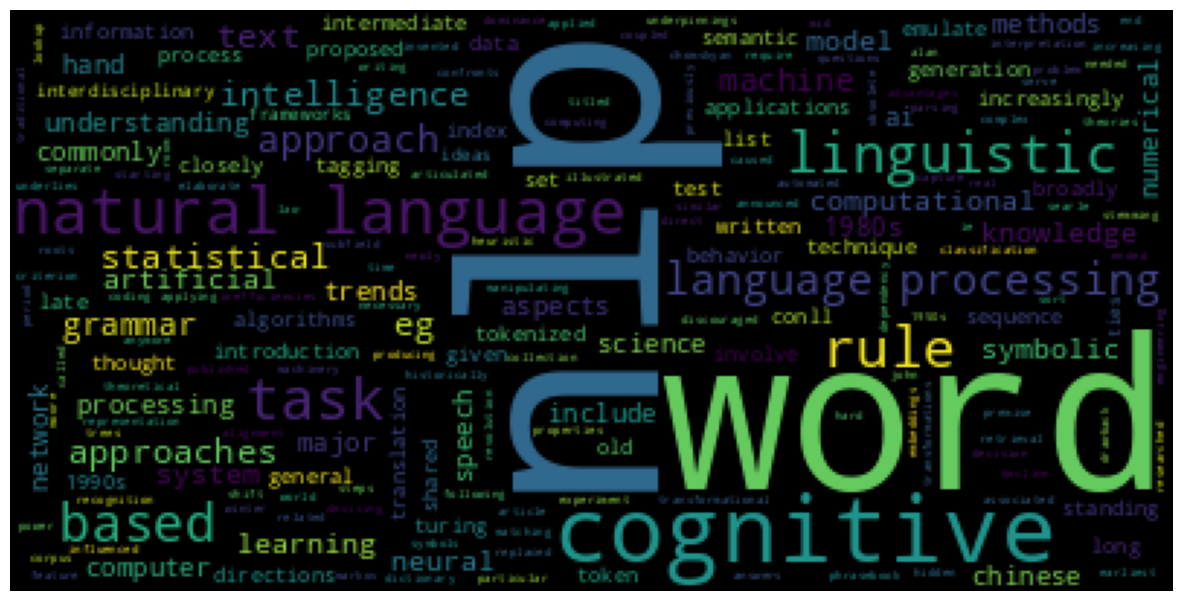

In [28]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt
cloud = WordCloud()
cloud = cloud.generate(article_cleaned)
plt.figure(figsize=(15,15))
plt.imshow(cloud)
plt.axis('off');

# Text summarization

- sumy library: https://pypi.org/project/sumy/

In [29]:
article.cleaned_text

'Natural language processing ( NLP ) is the processing of natural language information by a computer . NLP is a subfield of computer science and is closely associated with artificial intelligence . NLP is also related to information retrieval , knowledge representation , computational linguistics , and linguistics more broadly.\n\nMajor processing tasks in an NLP system include: speech recognition , text classification , natural language understanding , and natural language generation .\n\nNatural language processing has its roots in the 1950s. Already in 1950, Alan Turing published an article titled " Computing Machinery and Intelligence ," which proposed what is now called the Turing test as a criterion of intelligence, though at the time that was not articulated as a problem separate from artificial intelligence. The proposed test includes a task that involves the automated interpretation and generation of natural language.\n\nThe premise of symbolic NLP is often illustrated using J

In [30]:
original_sentences = [sentence for sentence in nltk.sent_tokenize(article.cleaned_text)]

In [31]:
original_sentences

['Natural language processing ( NLP ) is the processing of natural language information by a computer .',
 'NLP is a subfield of computer science and is closely associated with artificial intelligence .',
 'NLP is also related to information retrieval , knowledge representation , computational linguistics , and linguistics more broadly.',
 'Major processing tasks in an NLP system include: speech recognition , text classification , natural language understanding , and natural language generation .',
 'Natural language processing has its roots in the 1950s.',
 'Already in 1950, Alan Turing published an article titled " Computing Machinery and Intelligence ," which proposed what is now called the Turing test as a criterion of intelligence, though at the time that was not articulated as a problem separate from artificial intelligence.',
 'The proposed test includes a task that involves the automated interpretation and generation of natural language.',
 "The premise of symbolic NLP is often

In [32]:
len(original_sentences), 40 / 87

(42, 0.45977011494252873)

In [33]:
# !pip install sumy

In [34]:
from sumy.parsers.plaintext import PlaintextParser
from sumy.nlp.tokenizers import Tokenizer
from sumy.summarizers.sum_basic import SumBasicSummarizer

In [35]:
parser = PlaintextParser.from_string(article.cleaned_text, Tokenizer('english'))

In [36]:
summarizer = SumBasicSummarizer()
summary = summarizer(parser.document, 40)

In [37]:
summary

(<Sentence: NLP is a subfield of computer science and is closely associated with artificial intelligence .>,
 <Sentence: NLP is also related to information retrieval , knowledge representation , computational linguistics , and linguistics more broadly.>,
 <Sentence: Major processing tasks in an NLP system include: speech recognition , text classification , natural language understanding , and natural language generation .>,
 <Sentence: Natural language processing has its roots in the 1950s.>,
 <Sentence: Already in 1950, Alan Turing published an article titled " Computing Machinery and Intelligence ," which proposed what is now called the Turing test as a criterion of intelligence, though at the time that was not articulated as a problem separate from artificial intelligence.>,
 <Sentence: The proposed test includes a task that involves the automated interpretation and generation of natural language.>,
 <Sentence: The premise of symbolic NLP is often illustrated using John Searle's Chi

In [38]:
best_sentences = []
for sentence in summary:
  best_sentences.append(str(sentence))

In [39]:
best_sentences

['NLP is a subfield of computer science and is closely associated with artificial intelligence .',
 'NLP is also related to information retrieval , knowledge representation , computational linguistics , and linguistics more broadly.',
 'Major processing tasks in an NLP system include: speech recognition , text classification , natural language understanding , and natural language generation .',
 'Natural language processing has its roots in the 1950s.',
 'Already in 1950, Alan Turing published an article titled " Computing Machinery and Intelligence ," which proposed what is now called the Turing test as a criterion of intelligence, though at the time that was not articulated as a problem separate from artificial intelligence.',
 'The proposed test includes a task that involves the automated interpretation and generation of natural language.',
 "The premise of symbolic NLP is often illustrated using John Searle's Chinese room thought experiment: Given a collection of rules (e.g., a Chi

In [40]:
from IPython.core.display import HTML
text = ''
display(HTML(f'<h2>Summary - {article.title}</h2>'))
for sentence in original_sentences:
  #print(sentence)
  if sentence in best_sentences:
    text += ' ' + str(sentence).replace(sentence, f"<mark>{sentence}</mark>")
  else:
    text += ' ' + sentence
display(HTML(f"""{text}"""))

# Key word search

In [41]:
string = 'Natural language processing (NLP) is a subfield of linguistics, computer science, and artificial intelligence concerned with the interactions between computers and human language, in particular how to program computers to process and analyze large amounts of natural language data.'

In [42]:
search_strings = ['artificial', 'computer']
tokens_list = [nlp(item) for item in search_strings]

In [43]:
tokens_list

[artificial, computer]

In [44]:
from spacy.matcher import PhraseMatcher
matcher = PhraseMatcher(nlp.vocab)
matcher.add('SEARCH', None, *tokens_list)

In [45]:
document = nlp(string)
matches = matcher(document)
matches

[(8661325627334373315, 12, 13), (8661325627334373315, 16, 17)]

In [46]:
document[12:13], document[16:17]

(computer, artificial)

In [47]:
document[12-5:13+5]

a subfield of linguistics, computer science, and artificial intelligence

In [48]:
document[16-5:17+5]

, computer science, and artificial intelligence concerned with the interactions

In [49]:
number_of_words = 50
search_strings_html = ' '.join([element for element in search_strings])
search_strings_html

'artificial computer'

In [50]:
marked_text = ''
display(HTML(f'<h1>{search_strings_html.upper()}</h1>'))
document = nlp(article.cleaned_text)
matches = matcher(document)
#print(matches)
display(HTML(f"""<p><strong>Number of matches: </strong>{len(matches)}</p>"""))
for i in matches:
  #print(i)
  start = i[1] - number_of_words
  if start < 0:
    start = 0
  for j in range(len(tokens_list)):
    #print(j, tokens_list[j])
    if document[i[1]:i[2]].similarity(tokens_list[j]) == 1.0:
      search_text = str(tokens_list[j])
      marked_text += str(document[start:i[2] + number_of_words]).replace(search_text, f"<mark>{search_text}</mark>")
      marked_text += "<br /><br />"
display(HTML(f"""<blockquote>{marked_text}</blockquote>"""))

/var/folders/8t/4ttt_tc53hs994xcrmjg2p880000gn/T/ipykernel_5203/887847395.py:14: UserWarning: [W007] The model you're using has no word vectors loaded, so the result of the Span.similarity method will be based on the tagger, parser and NER, which may not give useful similarity judgements. This may happen if you're using one of the small models, e.g. `en_core_web_sm`, which don't ship with word vectors and only use context-sensitive tensors. You can always add your own word vectors, or use one of the larger models instead if available.
  if document[i[1]:i[2]].similarity(tokens_list[j]) == 1.0:


# Bag of words

In [51]:
from sklearn.feature_extraction.text import CountVectorizer
sentences = ['This is the first document.',
             'This document is the second document.',
             'And this is the third one.',
             'Is this the first document?']

In [52]:
sentences

['This is the first document.',
 'This document is the second document.',
 'And this is the third one.',
 'Is this the first document?']

In [53]:
vectorizer = CountVectorizer()
X = vectorizer.fit_transform(sentences)
print(vectorizer.get_feature_names_out())

['and' 'document' 'first' 'is' 'one' 'second' 'the' 'third' 'this']


In [54]:
X.toarray()

array([[0, 1, 1, 1, 0, 0, 1, 0, 1],
       [0, 2, 0, 1, 0, 1, 1, 0, 1],
       [1, 0, 0, 1, 1, 0, 1, 1, 1],
       [0, 1, 1, 1, 0, 0, 1, 0, 1]])

In [55]:
original_sentences

['Natural language processing ( NLP ) is the processing of natural language information by a computer .',
 'NLP is a subfield of computer science and is closely associated with artificial intelligence .',
 'NLP is also related to information retrieval , knowledge representation , computational linguistics , and linguistics more broadly.',
 'Major processing tasks in an NLP system include: speech recognition , text classification , natural language understanding , and natural language generation .',
 'Natural language processing has its roots in the 1950s.',
 'Already in 1950, Alan Turing published an article titled " Computing Machinery and Intelligence ," which proposed what is now called the Turing test as a criterion of intelligence, though at the time that was not articulated as a problem separate from artificial intelligence.',
 'The proposed test includes a task that involves the automated interpretation and generation of natural language.',
 "The premise of symbolic NLP is often

In [56]:
vectorizer = CountVectorizer()
X_sentences = vectorizer.fit_transform(original_sentences)
print(vectorizer.get_feature_names_out())

['1950' '1950s' '1980s' '1990s' '2015' '2020' 'above' 'achieve' 'acl'
 'acquiring' 'act' 'action' 'addressed' 'advanced' 'advantages' 'age' 'ai'
 'aid' 'alan' 'algorithms' 'alignment' 'along' 'already' 'also' 'although'
 'among' 'an' 'and' 'announced' 'answers' 'anymore' 'apparent'
 'applications' 'applied' 'applying' 'approach' 'approaches' 'are' 'area'
 'article' 'articulated' 'artificial' 'as' 'aspects' 'associated' 'at'
 'automated' 'bag' 'based' 'be' 'been' 'behavior' 'below' 'both'
 'boundaries' 'bow' 'branch' 'british' 'broadly' 'build' 'but' 'by'
 'called' 'can' 'capture' 'cases' 'categories' 'caused' 'chinese'
 'chomskyan' 'classification' 'closely' 'coarse' 'coding' 'cognition'
 'cognitive' 'collection' 'college' 'combining' 'commonly' 'complex'
 'components' 'comprehension' 'computational' 'computer' 'computing'
 'conferences' 'confronts' 'conll' 'construction' 'context' 'convenience'
 'corpus' 'corresponding' 'coupled' 'creation' 'criterion' 'data'
 'decision' 'decline' 'de

In [57]:
len(vectorizer.get_feature_names_out())

444

In [58]:
X_sentences.toarray()

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]])

In [59]:
X_sentences.toarray()[1]

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0,
       1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0,
       0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,

# TF-IDF

In [60]:
import math
1 + math.log(4 / 3)

1.2876820724517808

In [61]:
1 + math.log(4 / 2)

1.6931471805599454

In [62]:
1 + math.log(4 / 4)

1.0

In [63]:
sentences = ['This is the first document.',
             'This document is the second document.',
             'And this is the third one.',
             'Is this the first document?']

In [64]:
from sklearn.feature_extraction.text import TfidfVectorizer
vectorizer = TfidfVectorizer()
X = vectorizer.fit_transform(sentences)

In [65]:
vectorizer.get_feature_names_out()

array(['and', 'document', 'first', 'is', 'one', 'second', 'the', 'third',
       'this'], dtype=object)

In [66]:
vectorizer.idf_

array([1.91629073, 1.22314355, 1.51082562, 1.        , 1.91629073,
       1.91629073, 1.        , 1.91629073, 1.        ])

In [67]:
X.toarray()

array([[0.        , 0.46979139, 0.58028582, 0.38408524, 0.        ,
        0.        , 0.38408524, 0.        , 0.38408524],
       [0.        , 0.6876236 , 0.        , 0.28108867, 0.        ,
        0.53864762, 0.28108867, 0.        , 0.28108867],
       [0.51184851, 0.        , 0.        , 0.26710379, 0.51184851,
        0.        , 0.26710379, 0.51184851, 0.26710379],
       [0.        , 0.46979139, 0.58028582, 0.38408524, 0.        ,
        0.        , 0.38408524, 0.        , 0.38408524]])

In [68]:
original_sentences

['Natural language processing ( NLP ) is the processing of natural language information by a computer .',
 'NLP is a subfield of computer science and is closely associated with artificial intelligence .',
 'NLP is also related to information retrieval , knowledge representation , computational linguistics , and linguistics more broadly.',
 'Major processing tasks in an NLP system include: speech recognition , text classification , natural language understanding , and natural language generation .',
 'Natural language processing has its roots in the 1950s.',
 'Already in 1950, Alan Turing published an article titled " Computing Machinery and Intelligence ," which proposed what is now called the Turing test as a criterion of intelligence, though at the time that was not articulated as a problem separate from artificial intelligence.',
 'The proposed test includes a task that involves the automated interpretation and generation of natural language.',
 "The premise of symbolic NLP is often

In [69]:
vectorizer = TfidfVectorizer()
X_sentences = vectorizer.fit_transform(original_sentences)

In [70]:
print(vectorizer.get_feature_names_out())

['1950' '1950s' '1980s' '1990s' '2015' '2020' 'above' 'achieve' 'acl'
 'acquiring' 'act' 'action' 'addressed' 'advanced' 'advantages' 'age' 'ai'
 'aid' 'alan' 'algorithms' 'alignment' 'along' 'already' 'also' 'although'
 'among' 'an' 'and' 'announced' 'answers' 'anymore' 'apparent'
 'applications' 'applied' 'applying' 'approach' 'approaches' 'are' 'area'
 'article' 'articulated' 'artificial' 'as' 'aspects' 'associated' 'at'
 'automated' 'bag' 'based' 'be' 'been' 'behavior' 'below' 'both'
 'boundaries' 'bow' 'branch' 'british' 'broadly' 'build' 'but' 'by'
 'called' 'can' 'capture' 'cases' 'categories' 'caused' 'chinese'
 'chomskyan' 'classification' 'closely' 'coarse' 'coding' 'cognition'
 'cognitive' 'collection' 'college' 'combining' 'commonly' 'complex'
 'components' 'comprehension' 'computational' 'computer' 'computing'
 'conferences' 'confronts' 'conll' 'construction' 'context' 'convenience'
 'corpus' 'corresponding' 'coupled' 'creation' 'criterion' 'data'
 'decision' 'decline' 'de

In [71]:
len(vectorizer.get_feature_names_out())

444

In [72]:
X_sentences.toarray()

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]])

In [73]:
X_sentences.toarray()[1]

array([0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.15519459, 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.30510509, 0.        , 0.        , 0.36776839,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.33111271, 0.        , 0.        , 0.     

# Cosine similarity

- Link: https://en.wikipedia.org/wiki/Cosine_similarity
- Step by step calculation: https://janav.wordpress.com/2013/10/27/tf-idf-and-cosine-similarity/

In [74]:
X_sentences.shape

(42, 444)

In [75]:
type(X_sentences)

scipy.sparse._csr.csr_matrix

In [76]:
X_test_similarity = X_sentences[0:3]
X_test_similarity = X_test_similarity.toarray()

In [77]:
type(X_test_similarity)

numpy.ndarray

In [78]:
import numpy as np
X_test_similarity = np.concatenate((X_test_similarity, X_test_similarity[0].reshape(1,-1)), axis = 0)

In [79]:
X_test_similarity

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]])

In [80]:
X_test_similarity.shape

(4, 444)

In [81]:
from sklearn.metrics.pairwise import cosine_similarity

In [82]:
cosine_similarity(X_test_similarity[0].reshape(1,-1), X_test_similarity[1].reshape(1,-1))

array([[0.22134883]])

In [83]:
original_sentences[0]

'Natural language processing ( NLP ) is the processing of natural language information by a computer .'

In [84]:
original_sentences[1]

'NLP is a subfield of computer science and is closely associated with artificial intelligence .'

In [85]:
cosine_similarity(X_test_similarity[1].reshape(1,-1), X_test_similarity[2].reshape(1,-1))

array([[0.10126932]])

In [86]:
original_sentences[2]

'NLP is also related to information retrieval , knowledge representation , computational linguistics , and linguistics more broadly.'

In [87]:
cosine_similarity(X_test_similarity[0].reshape(1,-1), X_test_similarity[3].reshape(1,-1))

array([[1.]])

In [88]:
cosine_similarity(X_test_similarity[0].reshape(1,-1), X_test_similarity)

array([[1.        , 0.22134883, 0.1622755 , 1.        ]])

# Simulating a chatbot

In [89]:
welcome_words_input = ('hey', 'hello', 'hi')
welcome_words_ouput = ('hey', 'hello', 'hi', 'how are you?', 'welcome', 'how are you doing?')

In [90]:
'how are you'.split()

['how', 'are', 'you']

In [91]:
import random
def welcome_message(text):
  for word in text.split():
    if word.lower() in welcome_words_input:
      return random.choice(welcome_words_ouput)

In [92]:
welcome_message('hi')

'welcome'

In [93]:
welcome_message('hiii')

In [94]:
def answer(user_text, threshold = 0.3):
  cleaned_sentences = []
  for sentence in original_sentences:
    cleaned_sentences.append(preprocessing(sentence))
  #print(cleaned_sentences)

  chatbot_answer = ''
  user_text = preprocessing(user_text)
  #print(user_text)
  cleaned_sentences.append(user_text)
  #print(cleaned_sentences[-1])

  tfidf = TfidfVectorizer()
  X_sentences = tfidf.fit_transform(cleaned_sentences)
  #print(X_sentences.toarray()[-1])
  similarity = cosine_similarity(X_sentences[-1], X_sentences)
  #print(similarity)
  sentence_index = similarity.argsort()[0][-2]
  #print(sentence_index)
  #print(similarity[0][sentence_index])

  if similarity[0][sentence_index] < threshold:
    chatbot_answer += 'Sorry, no answer was found!'
  else:
    chatbot_answer += original_sentences[sentence_index]

  return chatbot_answer

In [95]:
answer('What is natural language processing?', 0.3)

'Natural language processing ( NLP ) is the processing of natural language information by a computer .'

In [96]:
answer('Who is Alan Turing')

'Already in 1950, Alan Turing published an article titled " Computing Machinery and Intelligence ," which proposed what is now called the Turing test as a criterion of intelligence, though at the time that was not articulated as a problem separate from artificial intelligence.'

In [97]:
answer('What is NLP')

'Sorry, no answer was found!'

In [98]:
cont = True
print('Hello! I am a chatbot and I will answer your questions about natural language processing')
while cont == True:
  user_text = input()
  if user_text != 'quit':
    if welcome_message(user_text) != None:
      print('Chatbot: ' + welcome_message(user_text))
    else:
      print('Chatbot:')
      print(answer(user_text))
  else:
    cont = False
    print('Chatbot: Bye! I will see you soon')

Hello! I am a chatbot and I will answer your questions about natural language processing
Chatbot:
Sorry, no answer was found!
Chatbot:
Sorry, no answer was found!
Chatbot:
Sorry, no answer was found!
Chatbot:
Sorry, no answer was found!
Chatbot:
Sorry, no answer was found!
Chatbot:
Sorry, no answer was found!
Chatbot:
Sorry, no answer was found!
Chatbot:
Sorry, no answer was found!
Chatbot:
Sorry, no answer was found!
Chatbot:
Sorry, no answer was found!
Chatbot:
Sorry, no answer was found!
Chatbot:
Sorry, no answer was found!
Chatbot:
Sorry, no answer was found!
Chatbot:
Sorry, no answer was found!
Chatbot:
Sorry, no answer was found!
Chatbot:
Sorry, no answer was found!
Chatbot:
Sorry, no answer was found!
Chatbot: how are you?
Chatbot:
Sorry, no answer was found!
Chatbot:
Sorry, no answer was found!
Chatbot: Bye! I will see you soon
